# 00 - Data Understanding (raw AHRI CEM export)
Rahel Genene and Hanna Getachw - DBU Data Science internship, Ministry of Health, Ethiopia

Purpose: describe the raw REDCap export (`dataset/CEM.csv`) before any cleaning: size, missingness, and identifier quality.
Outputs are written to `output/00_data_understanding/`. Run this notebook from the `notebook/` folder.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()
RAW = ROOT / 'dataset' / 'CEM.csv'
OUT = ROOT / 'output' / '00_data_understanding'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
(OUT / 'tables').mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(RAW, low_memory=False)
print('Rows, columns:', raw.shape)
print(raw.dtypes.astype(str).value_counts().to_string())

Rows, columns: (2506, 833)
str        512
float64    183
int64      138


## 1. Overall missingness

In [2]:
miss_pct = raw.isna().mean() * 100
overall = raw.isna().sum().sum() / raw.size * 100
print(f'Share of all cells that are empty: {overall:.1f}%')
print('Columns that are 100% empty :', int((miss_pct == 100).sum()))
print('Columns more than 90% empty :', int((miss_pct > 90).sum()))
print('Columns more than 50% empty :', int((miss_pct > 50).sum()))
print('Columns less than 10% empty :', int((miss_pct < 10).sum()))

col_missing = (pd.DataFrame({'column': miss_pct.index, 'missing_pct': miss_pct.values.round(2),
                             'n_missing': raw.isna().sum().values})
               .sort_values('missing_pct', ascending=False))
col_missing.to_csv(OUT / 'tables' / 'column_missingness.csv', index=False)
col_missing.head(10)

Share of all cells that are empty: 72.1%
Columns that are 100% empty : 121
Columns more than 90% empty : 498
Columns more than 50% empty : 621
Columns less than 10% empty : 158


,column,missing_pct,n_missing
794,date_vii_2_of_onset,100.0,2506
793,description_vii_2_of_pregn,100.0,2506
24,end_medicn_da1,100.0,2506
64,cpast_diseases4_name,100.0,2506
813,name_and_doses_of_medicati,100.0,2506
800,d3_abnormalities_of_foetus,100.0,2506
785,remark_on_the_drug_vii_3,100.0,2506
784,quantity_vii_3,100.0,2506
638,who_stage_at_visit_2fp,100.0,2506
65,cstart_date4,100.0,2506


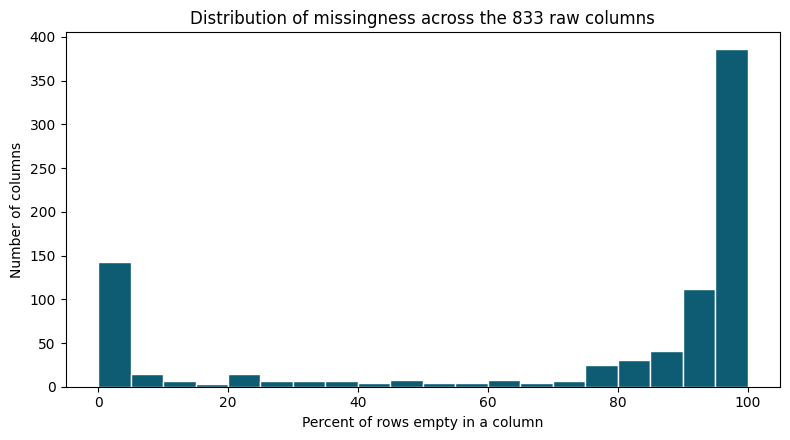

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(miss_pct, bins=20, color='#0e5c73', edgecolor='white')
ax.set_xlabel('Percent of rows empty in a column')
ax.set_ylabel('Number of columns')
ax.set_title('Distribution of missingness across the 833 raw columns')
plt.tight_layout()
plt.savefig(OUT / 'figures' / 'missingness_distribution.png', dpi=150)
plt.show()

## 2. Identifier quality
The CEM number entered by staff is not a reliable patient key on its own; this is why a reconciled `patient_id` was built in the pre-processing notebook.

In [4]:
id_col = 'patient_id_number_cem_no'
ids = raw[id_col].dropna().astype(str).str.strip()
summary = pd.DataFrame({
    'metric': ['rows in export', 'rows with a CEM number', 'distinct CEM numbers',
               'CEM numbers used by more than one row'],
    'value': [len(raw), len(ids), ids.nunique(), int((ids.value_counts() > 1).sum())]
})
summary.to_csv(OUT / 'tables' / 'identifier_quality.csv', index=False)
summary

,metric,value
0,rows in export,2506
1,rows with a CEM number,1838
2,distinct CEM numbers,963
3,CEM numbers used by more than one row,303


## 3. Facilities and sex (raw coding)

In [5]:
fac = raw['health_facility'].value_counts(dropna=False)
print('Distinct health_facility values:', raw['health_facility'].nunique())
fac.head(15).to_csv(OUT / 'tables' / 'top_facilities_raw.csv', header=['rows'])
print(fac.head(15).to_string())
print()
print('Raw sex coding (numeric codes as exported):')
print(raw['sex'].value_counts(dropna=False).to_string())

Distinct health_facility values: 47
health_facility
St Paul Hospital             266
Zewditu Hospital             235
Saries Health Center         199
Police Hospital              174
Gandhi Memorial Hospital     123
Kotebe Health Center         109
Menelik Hospital              90
Kaliti Health Center          77
Wereda 3 Health Center        76
Kolfe Health Center           75
Wereda 3 Health Center        74
Bole 17 Health Center         74
Alert Hospital                71
Black Lion Hospital           70
Arada Health Center           70

Raw sex coding (numeric codes as exported):
sex
2.0    1379
1.0     903
NaN     224


## Findings
- The export is very wide and sparse, so cleaning must be field-by-field and only well-populated fields can be modeled.
- CEM numbers repeat across rows, so a reconciled patient identifier is required (see `01_pre_processing.ipynb`).
- Next: `01_pre_processing.ipynb`.